# **1. Introduction**

Support Vector Classifier (SVC) is a supervised machine learning algorithm used for classification.

It finds a decision boundary, called a hyperplane, that separates classes. SVC tries to create the largest possible margin between different classes.

In this project, I use SVC to predict the species of an Iris flower based on four measurements:
- Sepal length
- Sepal width
- Petal length
- Petal width

The dataset contains three species: Setosa, Versicolor, and Virginica.

The project includes exploratory data analysis, feature scaling, hyperparameter tuning using cross-validation, and model evaluation.

# **2. Import Libraries**

Import the required libraries for data manipulation, visualization, preprocessing, model training, cross-validation, hyperparameter tuning, and evaluation.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# **3. Load Dataset**

Load the Iris dataset provided by Scikit-learn.

The dataset is available directly through `load_iris()`, so we do not need to download a separate CSV file.

Using `as_frame=True` loads the feature data and target in Pandas format.

In [24]:
# Load the Iris dataset
iris = load_iris(as_frame=True)

# Separate features and target
X = iris.data
y = iris.target

print("Dataset uploaded successfully")

Dataset uploaded successfully


In [25]:
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


# **4. Understand the Dataset**

Display the number of rows and columns, inspect the data types, and check whether the dataset contains missing values.

In [26]:
# Display the dataset shape
print("Dataset Shape:", X.shape)

Dataset Shape: (150, 4)


In [27]:
# Display column data types and non-null counts
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB


In [28]:
# Check missing values in each feature
X.isnull().sum()

,0
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0


# **5. Statistical Summary**

Use `describe()` to calculate statistical measures such as mean, standard deviation, minimum, maximum, and quartiles for each numerical feature.

`.T` transposes the output so that each feature appears as a row.

In [29]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


# **6. Target Distribution**

The target variable represents the Iris flower species.

- 0 represents Setosa.
- 1 represents Versicolor.
- 2 represents Virginica.

Check the number and percentage of observations in each class to understand the target distribution.

In [30]:
# Display the number of observations in each class
print(y.value_counts().sort_index())

# Display the percentage of each class
print(y.value_counts(normalize=True).sort_index() * 100)

target
0    50
1    50
2    50
Name: count, dtype: int64
target
0    33.333333
1    33.333333
2    33.333333
Name: proportion, dtype: float64


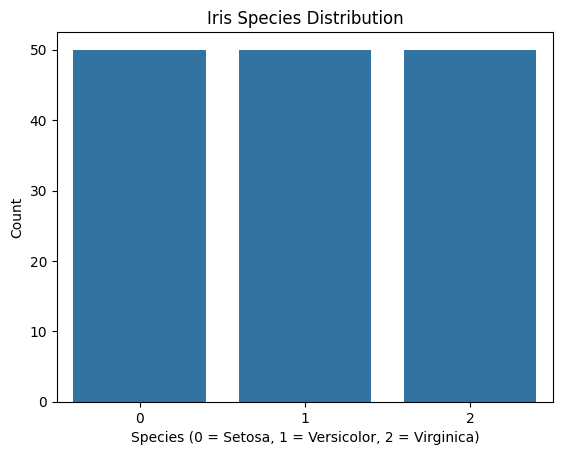

In [31]:
# Visualize the target distribution
sns.countplot(x=y)

plt.title("Iris Species Distribution")
plt.xlabel("Species (0 = Setosa, 1 = Versicolor, 2 = Virginica)")
plt.ylabel("Count")
plt.show()

### Interpretation
The graph shows three bars of equal height. Setosa, Versicolor, and Virginica each contain 50 observations, making 150 flowers in total. Therefore, the target classes are balanced, and no species is over-represented.

# **7. Create a Working DataFrame**

Combine the input features and target variable into one DataFrame for exploratory data analysis.

The numeric target values are replaced with readable species names in the `species` column. The original target variable `y` remains unchanged for model training.

In [32]:
# Create a copy of the feature DataFrame
df = X.copy()

# Add readable species names
df["species"] = y.map(dict(enumerate(iris.target_names)))

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


# **8. Exploratory Data Analysis (EDA)**

Exploratory Data Analysis helps us understand the dataset before building a machine learning model.

In this section, I will examine feature distributions, compare measurements across species, and study relationships between numerical features.

## **8.1 Feature Distributions**

Histograms show how the values of each numerical feature are distributed.

They help us understand the range, spread, and shape of the feature distributions.

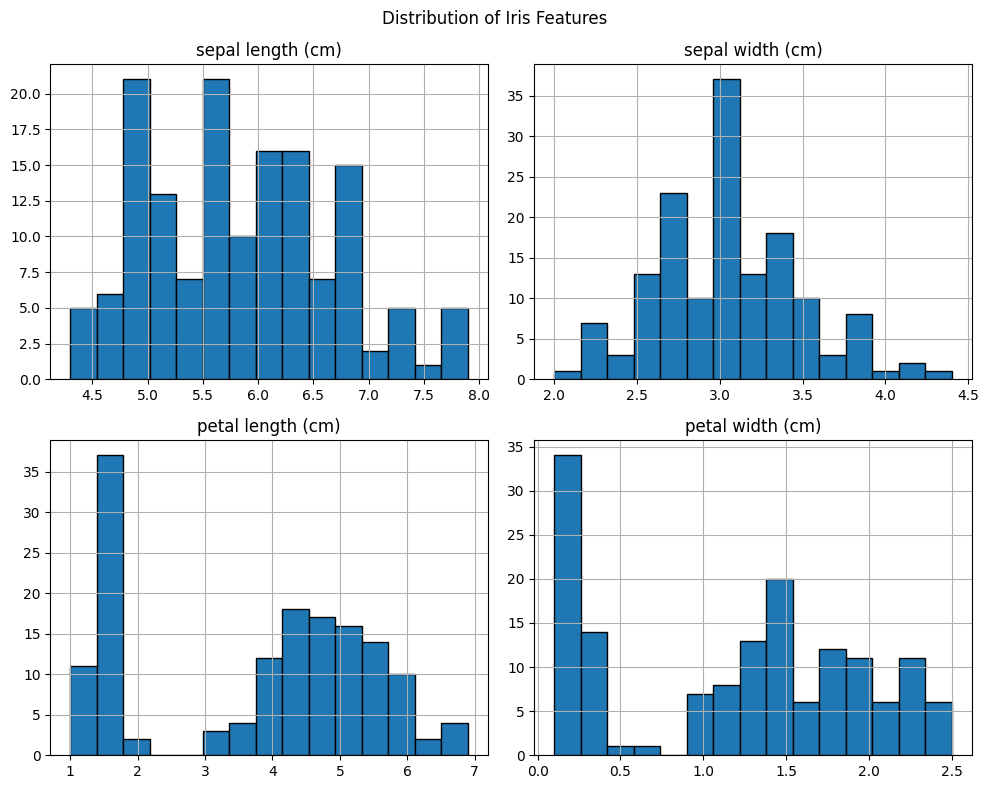

In [33]:
# Plot histograms for all numerical features
X.hist(figsize=(10, 8), bins=15, edgecolor="black")

plt.suptitle("Distribution of Iris Features")
plt.tight_layout()
plt.show()

### Interpretation
The histograms show the frequency of different measurement values for each feature. Petal length and petal width show noticeable groupings in their value ranges, while sepal length and sepal width have more overlapping distributions. The features also have different scales, which supports using StandardScaler before training SVC.

## **8.2 Compare Features Across Species**

Boxplots compare the distribution of each feature across the three Iris species.

They help identify differences in measurements and possible outliers.

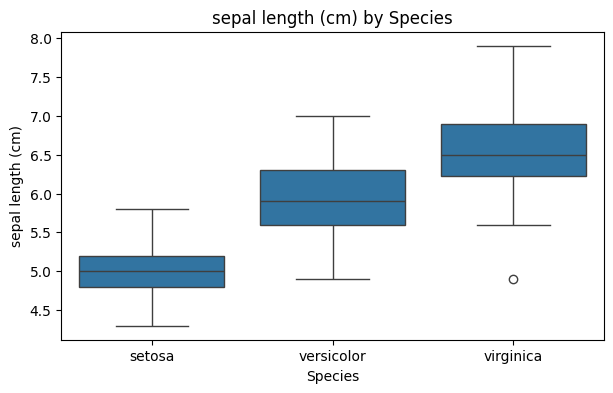

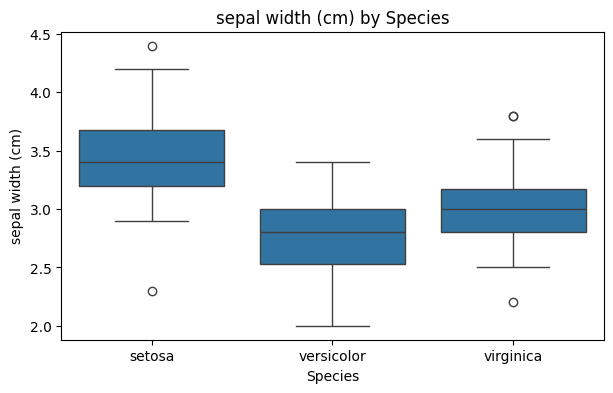

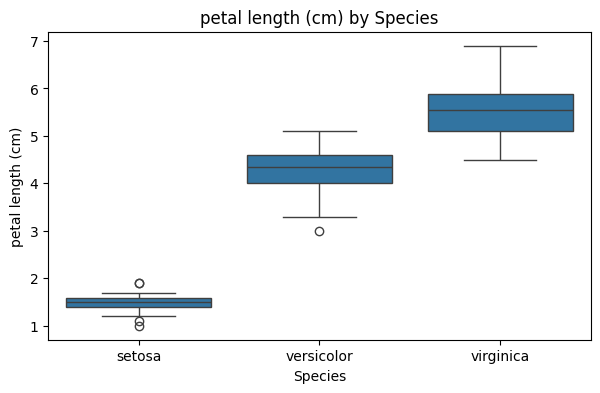

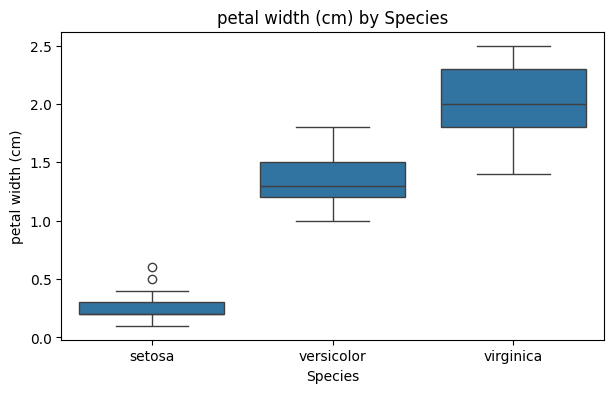

In [34]:
# Compare each feature across species
for column in X.columns:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="species",
        y=column
    )

    plt.title(f"{column} by Species")
    plt.xlabel("Species")
    plt.ylabel(column)
    plt.show()

### Interpretation
Each boxplot compares one feature across the three species. The middle line represents the median, the box represents the middle 50% of values, and the whiskers show the spread. Petal length and petal width generally show clearer differences between species, while sepal measurements overlap more. Greater separation suggests that a feature may help the SVC distinguish species.

## **8.3 Correlation Between Features**

Correlation measures the strength and direction of a linear relationship between numerical features.

A heatmap makes these relationships easier to understand. Correlation does not necessarily mean causation.

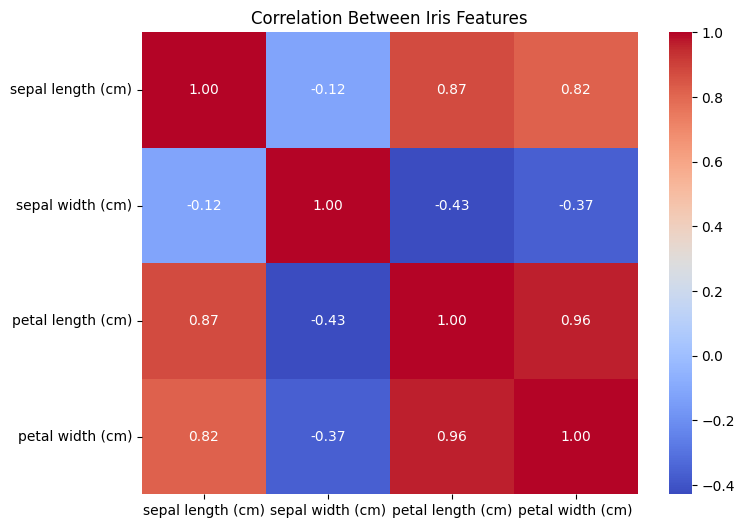

In [35]:
# Calculate and visualize feature correlations
plt.figure(figsize=(8, 6))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Iris Features")
plt.show()

### Interpretation
The heatmap displays the correlation between every pair of numerical features. Values near +1 indicate a strong positive linear relationship, values near -1 indicate a strong negative relationship, and values near 0 indicate a weak linear relationship. In this dataset, petal length and petal width have a strong positive correlation: flowers with longer petals generally also have wider petals. Correlation does not mean that one feature causes the other.

## **8.4 Pairplot**

A pairplot displays pairwise relationships between numerical features.

The `hue` parameter uses different colors for different species, helping us observe how the species are distributed across feature combinations.

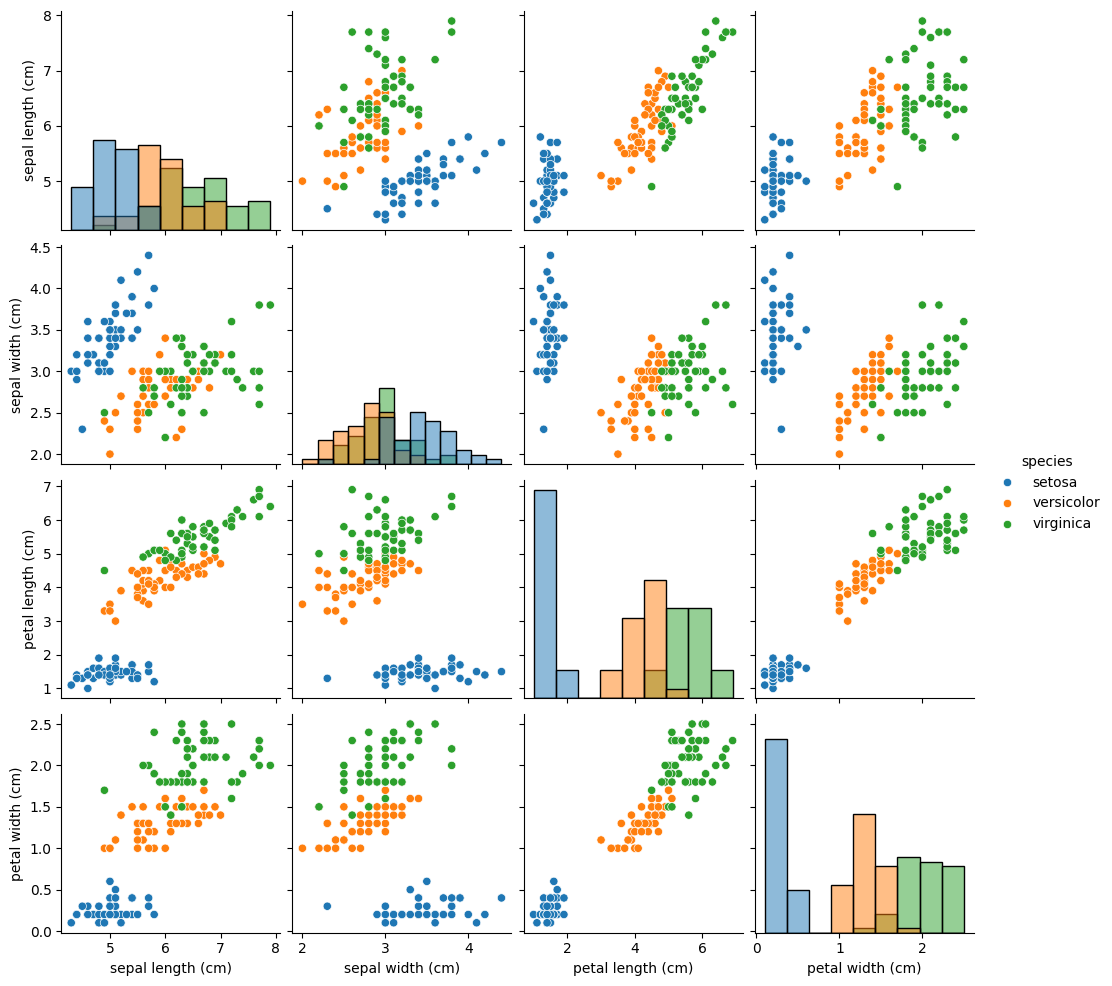

In [36]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.show()

### Interpretation
Each point represents one flower, and the colours identify its species. The diagonal plots show individual feature distributions; the other plots show relationships between pairs of features. Setosa forms a clearly separate cluster, particularly for petal length and petal width. Versicolor and Virginica overlap more, so distinguishing these two species can be more difficult. This overlap may explain some incorrect predictions.

# **9. Separate Features and Target**

The input features (`X`) contain the four flower measurements used for prediction.

The target (`y`) contains the numeric species labels that the model will learn to predict.

In [37]:
# Display the input features
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [38]:
# Display the target variable
y.head()

,target
0,0
1,0
2,0
3,0
4,0


# **10. Train-Test Split**

Split the dataset into training and testing sets.

- Training set: Used to train and tune the model.
- Testing set: Used for final evaluation on unseen observations.

I will use `stratify=y` to maintain approximately the same proportion of all three species in both sets.

In [39]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (120, 4)
X_test: (30, 4)
y_train: (120,)
y_test: (30,)


# **11. Build the SVC Pipeline**

SVC is sensitive to feature scales because it uses distances and margins to find decision boundaries.

I will create a Pipeline containing two steps:

1. StandardScaler: Standardizes features so they have comparable scales.
2. SVC: Classifies flower species using Support Vector Classification.

I will use the RBF kernel, which can learn nonlinear decision boundaries.

Using a Pipeline ensures that scaling is fitted only on the training portion during cross-validation, helping prevent data leakage.

In [40]:
# Create a pipeline for feature scaling and SVC classification
svc_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(probability=True, random_state=42))
])

svc_pipeline

Pipeline(steps=[('scaler', StandardScaler()),
                ('svc', SVC(probability=True, random_state=42))])

# **12. Hyperparameter Tuning Using Cross-Validation**

SVC has important hyperparameters that affect how the model learns.

- `C`: Controls the trade-off between a wider margin and classification errors. A smaller value allows a wider margin with more violations; a larger value penalizes errors more strongly.
- `kernel`: Defines the type of decision boundary. I will compare linear, RBF, and polynomial kernels.
- `gamma`: Controls how far the influence of an individual training observation reaches when using the RBF or polynomial kernel.

I will use GridSearchCV with 5-fold Stratified Cross-Validation to compare combinations of these parameters.

The model will be selected using accuracy because the Iris dataset has balanced classes.

In [53]:
# Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
# Define hyperparameter combinations to test
param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__kernel": ["linear", "rbf", "poly"],
    "svc__gamma": ["scale", "auto"]
}

# Evaluate using accuracy
grid_search = GridSearchCV(
    estimator=svc_pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

# Train and compare the models
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

Best Parameters: {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Best Cross-Validation Accuracy: 0.975


# **13. Compare Cross-Validation Results**

Display the cross-validation results for the different hyperparameter combinations.

This helps us understand how changing `C`, `kernel`, and `gamma` affects the model's mean validation accuracy.

In [42]:
# Convert cross-validation results into a DataFrame
cv_results = pd.DataFrame(grid_search.cv_results_)

# Select relevant columns
cv_results = cv_results[
    [
        "param_svc__C",
        "param_svc__kernel",
        "param_svc__gamma",
        "mean_test_score",
        "std_test_score"
    ]
]

# Rename columns for clarity
cv_results.columns = [
    "C",
    "Kernel",
    "Gamma",
    "Mean CV Accuracy",
    "Standard Deviation"
]

# Sort results by mean cross-validation accuracy
cv_results = cv_results.sort_values(
    by="Mean CV Accuracy",
    ascending=False
)

cv_results.head(10)

,C,Kernel,Gamma,Mean CV Accuracy,Standard Deviation
0,0.1,linear,scale,0.975000,0.020412
3,0.1,linear,auto,0.975000,0.020412
6,1.0,linear,scale,0.975000,0.033333
9,1.0,linear,auto,0.975000,0.033333
23,100.0,poly,auto,0.975000,0.020412
20,100.0,poly,scale,0.975000,0.020412
10,1.0,rbf,auto,0.966667,0.016667
7,1.0,rbf,scale,0.966667,0.016667
15,10.0,linear,auto,0.966667,0.031180
16,10.0,rbf,auto,0.966667,0.016667


# **14. Visualize Hyperparameter Results**

Visualize the mean cross-validation accuracy for the tested parameter combinations.

This comparison helps identify which kernel and parameter settings performed well during cross-validation.

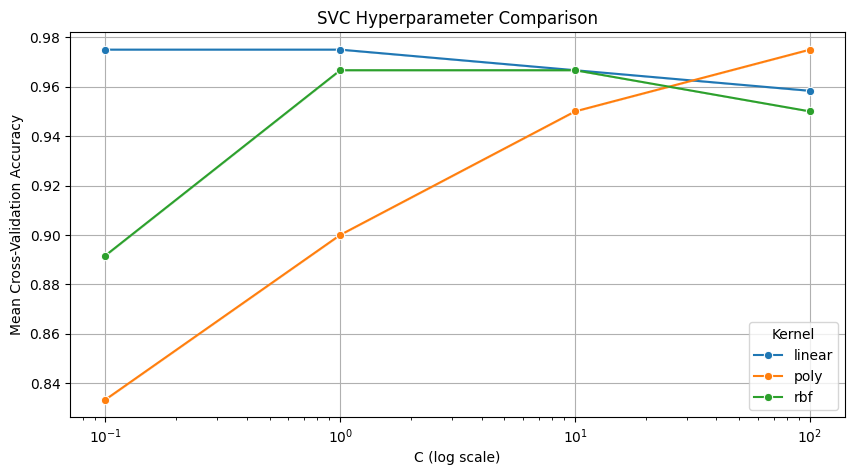

In [43]:
# Compare the mean cross-validation accuracy for each kernel and C value
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=cv_results,
    x="C",
    y="Mean CV Accuracy",
    hue="Kernel",
    marker="o"
)

plt.xscale("log")
plt.title("SVC Hyperparameter Comparison")
plt.xlabel("C (log scale)")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.grid(True)
plt.show()

### Interpretation
Each line represents one kernel (linear, RBF, or polynomial), and each point shows its mean accuracy across the five cross-validation folds for a particular C value. Higher points indicate better average validation performance. Compare the lines to see which kernel and C value perform best. The x-axis uses a logarithmic scale because the tested C values differ by powers of ten. GridSearchCV selects the combination with the highest mean cross-validation accuracy; a larger C does not automatically mean a better model.

# **15. Select the Best SVC Model**

GridSearchCV identifies the parameter combination with the highest mean cross-validation accuracy.

`best_estimator_` returns the complete best pipeline, including the fitted scaler and selected SVC model.

In [44]:
# Retrieve the best pipeline found during cross-validation
best_svc = grid_search.best_estimator_

print("Best Model:")
print(best_svc)

Best Model:
Pipeline(steps=[('scaler', StandardScaler()),
                ('svc',
                 SVC(C=0.1, kernel='linear', probability=True,
                     random_state=42))])


# **16. Make Predictions**

Use the selected model to predict the species for the unseen testing data.

The fitted pipeline automatically standardizes the testing features before making predictions.

In [45]:
# Predict the species for the testing data
y_pred = best_svc.predict(X_test)

# Display the first ten actual and predicted values
predictions = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

predictions["Actual Species"] = iris.target_names[predictions["Actual"]]
predictions["Predicted Species"] = iris.target_names[predictions["Predicted"]]

predictions.head(10)

,Actual,Predicted,Actual Species,Predicted Species
0,0,0,setosa,setosa
1,2,2,virginica,virginica
2,1,1,versicolor,versicolor
3,1,1,versicolor,versicolor
4,0,0,setosa,setosa
5,1,1,versicolor,versicolor
6,0,0,setosa,setosa
7,0,0,setosa,setosa
8,2,2,virginica,virginica
9,1,1,versicolor,versicolor


# **17. Model Evaluation**

Evaluate the selected model using the following metrics:

- Accuracy: Proportion of all predictions that are correct.
- Precision: Proportion of predicted samples of a class that actually belong to that class.
- Recall: Proportion of actual samples of a class that are correctly identified.
- F1-Score: Harmonic mean of precision and recall.

Because this is a multiclass classification problem, I will use the weighted average to calculate one overall precision, recall, and F1-score.

In [46]:
# Calculate classification metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

# Store the results in a DataFrame
evaluation = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [accuracy, precision, recall, f1]
})

evaluation

,Metric,Score
0,Accuracy,0.933333
1,Precision,0.933333
2,Recall,0.933333
3,F1-Score,0.933333


# **18. Classification Report**

Display precision, recall, F1-score, and the number of observations for each species.

This report helps us understand how well the model identifies Setosa, Versicolor, and Virginica separately.

In [47]:
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names,
    digits=4
))

              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



# **19. Confusion Matrix**

A confusion matrix compares actual classes with predicted classes.

- Diagonal cells show correctly classified observations.
- Off-diagonal cells show incorrectly classified observations.

For this multiclass problem, each row represents an actual species and each column represents a predicted species.

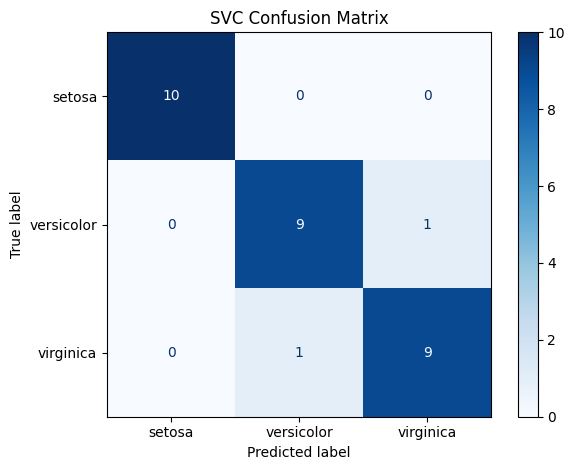

In [48]:
# Calculate and visualize the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names,
    cmap="Blues",
    values_format="d"
)

plt.title("SVC Confusion Matrix")
plt.tight_layout()
plt.show()

### Interpretation
Rows show the actual species, while columns show the species predicted by the model. The diagonal cells contain correct predictions; cells outside the diagonal show mistakes. A good result has large values on the diagonal and small or zero values elsewhere. If an off-diagonal value appears, use its row and column to identify which two species were confused. Each row total represents the number of actual test observations for that species.

# **20. Multiclass ROC Curve and AUC**

The ROC curve shows the relationship between the True Positive Rate and False Positive Rate at different classification thresholds.

The Iris dataset contains three classes. Therefore, I will use a One-vs-Rest approach:
- Setosa versus the other two species.
- Versicolor versus the other two species.
- Virginica versus the other two species.

`predict_proba()` provides a probability for each class. `label_binarize()` converts the actual labels into a binary format for plotting each class's ROC curve.

The macro AUC calculates the average AUC across the three classes, giving each class equal weight.

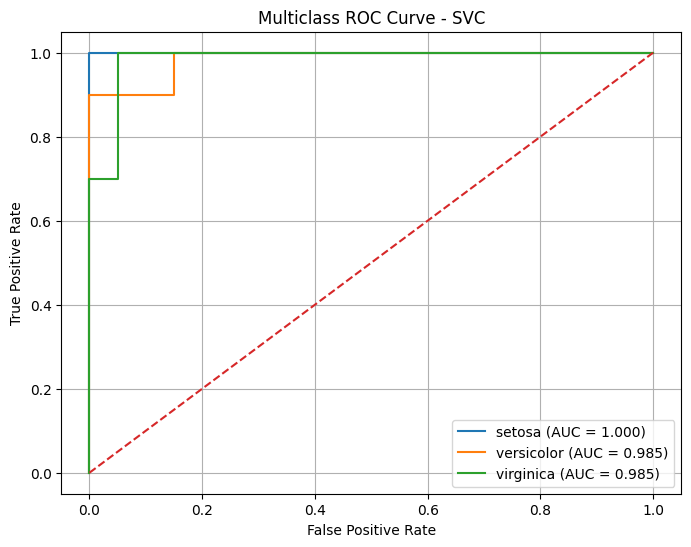

Macro OvR ROC-AUC: 0.9899999999999999


In [49]:
# Obtain predicted probabilities for all three classes
y_probability = best_svc.predict_proba(X_test)

# Convert actual labels into a binary format
y_test_binary = label_binarize(
    y_test,
    classes=[0, 1, 2]
)

# Plot one ROC curve for each class
plt.figure(figsize=(8, 6))

for i, class_name in enumerate(iris.target_names):
    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        y_probability[:, i]
    )

    class_auc = roc_auc_score(
        y_test_binary[:, i],
        y_probability[:, i]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {class_auc:.3f})"
    )

# Plot the random classifier reference line
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve - SVC")
plt.legend()
plt.grid(True)
plt.show()

# Calculate macro one-vs-rest AUC
macro_auc = roc_auc_score(
    y_test,
    y_probability,
    multi_class="ovr",
    average="macro"
)

print("Macro OvR ROC-AUC:", macro_auc)

### Interpretation
Each curve measures how well the model identifies one species while treating the other two species as the negative class (one-vs-rest). The x-axis is the False Positive Rate (FPR), and the y-axis is the True Positive Rate (TPR). Curves closer to the top-left corner indicate better class separation. The dashed diagonal represents random classification. AUC values closer to 1 indicate stronger separation, while a value near 0.5 indicates performance similar to random ranking. Compare the three AUC values in the legend; the printed macro AUC gives equal importance to all three species.

# **21. Inspect Incorrect Predictions**

Identify the observations where the actual species differs from the predicted species.

This helps us understand which flower species the model confuses.

In [50]:
# Filter incorrect predictions
errors = predictions[
    predictions["Actual"] != predictions["Predicted"]
]

print("Number of incorrect predictions:", len(errors))
errors

Number of incorrect predictions: 2


,Actual,Predicted,Actual Species,Predicted Species
23,2,1,virginica,versicolor
25,1,2,versicolor,virginica


# **22. Inspect Support Vectors**

Support vectors are the training observations that help determine the position of the SVC decision boundary.

The `n_support_` attribute gives the number of support vectors for each class.

These observations are important because they influence the learned boundary between classes.

In [51]:
# Access the SVC model from the best pipeline
svc_model = best_svc.named_steps["svc"]

print("Number of support vectors for each class:", svc_model.n_support_)
print("Total number of support vectors:", svc_model.n_support_.sum())

Number of support vectors for each class: [ 6 28 22]
Total number of support vectors: 56


# **23. Conclusion**

In this project, I implemented a Support Vector Classifier (SVC) using the Iris dataset.

I performed exploratory data analysis to understand the dataset, examined feature distributions and relationships, and split the data into training and testing sets.

I created a Pipeline using StandardScaler and SVC to ensure that feature scaling was performed correctly. I applied 5-fold Stratified Cross-Validation with GridSearchCV to select the best combination of SVC hyperparameters.

Finally, I evaluated the selected model using accuracy, precision, recall, F1-score, a classification report, a confusion matrix, and multiclass ROC-AUC. I also inspected incorrect predictions and the number of support vectors.


This project helped me understand how SVC works, why feature scaling is important, how kernels affect decision boundaries, and how cross-validation can be used for hyperparameter selection.